# Otimização de entregas com capacidade e janelas de tempo — Apresentação e pré-análise

**Pergunta de negócio.** Como alocar clientes a veículos e ordenar entregas minimizando primeiro a frota e depois a distância, sem violar capacidade e janelas?

**Enquadramento: analytics prescritivo.** O produto final deste projeto não é uma previsão nem uma descrição, e sim um *plano de rotas* — para cada veículo, a lista ordenada de clientes — que pode ser verificado de forma independente (capacidade, janelas e retorno ao depósito) e comparado com referências publicadas. A decisão é combinatória: quais clientes dividem um veículo e em que ordem são visitados. Trata-se de uma variante do problema de roteamento de veículos (Dantzig & Ramser, 1959) com janelas de tempo (Toth & Vigo, 2014).

**O que o benchmark de Solomon mede (Solomon, 1987).** A qualidade de planos de rotas em instâncias sintéticas com 100 clientes, um depósito, frota homogênea, distância euclidiana no plano e tempo de viagem igual à distância (velocidade 1). As janelas de tempo são rígidas para o *início* do serviço: chegar antes da abertura obriga o veículo a esperar, e chegar depois do fechamento torna o plano infactível. Esta é uma **convenção do benchmark**, não uma regra da operação real: na prática, a entrega antecipada costuma ser aceita quando o cliente está disponível, e o tempo poupado pode ser aproveitado no restante da rota. Esse relaxamento é tratado como cenário de negócio (Camada B), separado da comparação com o benchmark.

**O que o benchmark NÃO mede.** Rede viária, trânsito, tempos de viagem variáveis, custo de motorista, frota heterogênea, pedidos dinâmicos, janelas múltiplas ou atraso tolerado com penalidade. Não se trata de telemetria logística real, e resultados aqui não devem ser lidos como previsões de desempenho operacional.

**Relação com o projeto Olist.** A ligação é **temática, não empírica**: o projeto Olist trata de pedidos e entregas de um marketplace, mas seus dados não contêm frota, capacidade, janelas de tempo nem rotas. Nenhum dado do Olist é usado aqui.

**Roteiro.** Este notebook documenta os dados e as convenções de comparação (proveniência, inventário, contrato de dados, convenções de objetivo e decisões metodológicas). O notebook 02 realiza a análise exploratória das instâncias. Nenhum solver é executado em nenhum dos dois.

## 1. Preparação do ambiente

Nesta seção são carregadas as 56 instâncias (arquivo do SINTEF) e as duas tabelas de referência: a do SINTEF (SINTEF, 2008; veículos e distância, convenção hierárquica) e a do CVRPLIB (CVRPLIB, s.d.; rotas e custo publicados, convenção de distância truncada). Os caminhos vêm de `paths.data_paths()`, de modo que o notebook funciona a partir de qualquer pasta dentro do projeto. A tabela mostra quantos objetos foram lidos de cada fonte.

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import benchmark, eda, io, paths, viz_eda
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
instances = io.read_archive(P["sintef_zip"])
sintef = io.read_references(P["sintef_bks"])
cvrplib = io.read_cvrplib_references(P["cvrplib_bks"])

display(eda.localize_columns(eda.loaded_counts(instances, sintef, cvrplib, LANG), LANG))

,Item,Quantidade
0,Instâncias carregadas (SINTEF),56
1,"Referências SINTEF (veículos, distância)",56
2,"Referências CVRPLIB (rotas, custo)",56


**Insight.** Foram carregadas 56 instâncias do arquivo do SINTEF, 56 referências do SINTEF (veículos e distância) e 56 soluções do CVRPLIB (rotas e custo): as três fontes cobrem exatamente o mesmo conjunto de 56 instâncias, de modo que nenhuma comparação posterior precisará descartar casos. **Limitação:** a tabela do SINTEF foi transcrita manualmente de uma página salva em PDF; a contagem confere, mas a transcrição não é verificada por hash. **Próxima decisão:** confirmar a integridade dos arquivos de origem (seção seguinte).

## 2. Proveniência dos dados

**Pergunta:** os arquivos versionados no repositório são exatamente os que foram baixados e registrados? **Métrica:** SHA-256 de cada arquivo comparado com o valor anotado no `MANIFEST.md` da respectiva fonte. A tabela mostra, por arquivo, o resumo calculado, o resumo registrado (ambos abreviados) e se os resumos completos coincidem.

In [2]:
display(eda.localize_columns(eda.provenance_table(P), LANG))

,Arquivo,SHA-256 calculado,SHA-256 do MANIFEST,Confere
0,solomon-100.zip,8a0a72cbe6b7f8f9…,8a0a72cbe6b7f8f9…,True
1,Solomon.7z,55ba67b56a478554…,55ba67b56a478554…,True
2,Solomon-solutions.7z,88a5d385c0faf63e…,88a5d385c0faf63e…,True


**Insight.** Os três arquivos versionados (`solomon-100.zip`, `Solomon.7z` e `Solomon-solutions.7z`) têm SHA-256 idêntico ao registrado nos respectivos `MANIFEST.md` (3 de 3 com `Confere = True`). Observa-se, portanto, que os dados usados são os baixados em 17/11/2026. **Limitação:** o hash prova que o arquivo não mudou, não que a fonte seja correta; a tabela de referência do SINTEF (CSV transcrito) e o CSV derivado do CVRPLIB não são cobertos por esta verificação. **Próxima decisão:** como a integridade está confirmada, o inventário pode partir dos arquivos versionados.

## 3. Inventário por família

**Pergunta:** que estrutura têm as seis famílias de Solomon? As letras indicam a distribuição espacial (C = agrupados, R = aleatórios, RC = mistos) e o dígito indica a série (1 = horizonte curto e rotas com poucos clientes; 2 = horizonte longo e capacidade maior). A tabela mostra, por família, número de instâncias, de clientes, limite de frota (K), capacidade (Q), horizonte, tempo de serviço (mediana entre clientes) e demanda total média.

In [3]:
display(eda.localize_columns(eda.family_summary(instances), LANG))

,Família,Nº de instâncias,Nº de clientes,Limite de frota (K),Capacidade (Q),Horizonte,Tempo de serviço,Demanda total média
0,C1,9,100,25,200,1236,90.0,1810.0
1,C2,8,100,25,700,3390,90.0,1810.0
2,R1,12,100,25,200,230,10.0,1458.0
3,R2,11,100,25,1000,1000,10.0,1458.0
4,RC1,8,100,25,200,240,10.0,1724.0
5,RC2,8,100,25,1000,960,10.0,1724.0


**Insight.** As 56 instâncias distribuem-se em seis famílias (C1: 9, C2: 8, R1: 12, R2: 11, RC1: 8, RC2: 8), todas com 100 clientes e limite de frota K = 25. A capacidade é 200 nas séries 1 (C1, R1, RC1), 700 em C2 e 1000 em R2 e RC2; o horizonte vai de 230 (R1) a 3390 (C2); o tempo de serviço é 90 nas famílias C e 10 nas famílias R e RC. A demanda total média é igual dentro de cada classe entre as duas séries (1810 em C, 1458 em R, 1724 em RC), isto é, o que muda da série 1 para a série 2 são capacidade e horizonte, não a carga total. **Limitação:** as médias por família não mostram a variação interna, examinada no notebook 02. **Próxima decisão:** verificar se todas as instâncias cumprem o contrato de dados.

## 4. Contrato de dados

O contrato abaixo foi definido antes de qualquer análise e é verificado por regra e por instância.

| Campo | Unidade | Regra |
|---|---|---|
| `VEHICLE NUMBER` (K) | veículos | limite superior da frota |
| `CAPACITY` (Q) | unidades de demanda | mesma capacidade para todos os veículos |
| Nó 0 | — | depósito: demanda 0, tempo de serviço 0; `DUE DATE` = fim do horizonte |
| `XCOORD`, `YCOORD` | unidades de distância | inteiros; plano euclidiano |
| `DEMAND` | unidades de demanda | inteiro ≥ 0; ≤ capacidade |
| `READY TIME` / `DUE DATE` | unidades de tempo (= distância) | `READY` ≤ `DUE` ≤ horizonte; janela rígida para o início do serviço |
| `SERVICE TIME` | unidades de tempo | constante por família |
| IDs | — | 0..100, contíguos |

**Pergunta:** quantas das instâncias cumprem cada regra? A tabela mostra, por regra, o número de instâncias conformes.

In [4]:
check = eda.contract_check(instances)
display(eda.localize_columns(eda.contract_summary(check, LANG), LANG))

,Regra,Instâncias conformes,Nº de instâncias
0,IDs contíguos,56,56
1,Depósito sem demanda/serviço,56,56
2,Demanda ≤ capacidade,56,56
3,Início ≤ fim da janela,56,56
4,Janelas dentro do horizonte,56,56
5,Todas as regras,56,56


**Insight.** Todas as 56 instâncias cumprem as cinco regras do contrato (56 de 56 em cada linha, inclusive `Todas as regras`); nenhuma foi excluída. **Limitação:** o leitor de instâncias já rejeita arquivos que violam o contrato, então esta tabela documenta a conformidade, mas não constitui uma verificação independente do leitor; a regra de IDs contíguos é verificada aqui pelo comprimento consistente dos vetores. **Próxima decisão:** manter as 56 instâncias e passar às convenções de objetivo.

## 5. Convenções de objetivo: SINTEF × CVRPLIB

As duas fontes publicam soluções de referência sob convenções diferentes. **SINTEF:** objetivo hierárquico (primeiro o número de veículos, depois a distância total; Bräysy & Gendreau, 2005a; SINTEF, 2008), cálculo em precisão dupla, distância total arredondada a 2 casas. **CVRPLIB:** objetivo apenas de distância total (com até K rotas), distância euclidiana truncada em 1 casa decimal (CVRPLIB, s.d.), custo com 1 casa.

**Pergunta:** o que muda quando as rotas do CVRPLIB são re-verificadas por um verificador independente sob cada convenção, e como se comparam com o SINTEF? **Métricas:** factibilidade (capacidade, janelas, retorno ao depósito) com distância truncada e com distância exata; reprodução do custo publicado (tolerância de 0,05); diferença de veículos; e, nas instâncias de frota igual, reprodução da distância do SINTEF (tolerância de 0,01). A tabela resume as contagens; o gráfico mostra, por instância, a diferença de veículos SINTEF − CVRPLIB (eixo x; valores negativos indicam menos veículos no SINTEF) e quanto a distância do SINTEF supera a das rotas do CVRPLIB recalculadas com distância exata (eixo y, em %).

,Indicador,Valor
0,Instâncias comparadas,56
1,Soluções CVRPLIB factíveis com distância truncada,56
2,"Custo publicado reproduzido (±0,05) com distân...",56
3,Soluções CVRPLIB factíveis com distância exata,48
4,Instâncias infactíveis com distância exata,"8: R102, R105, R107, R108, R112, R211, RC101, ..."
5,Instâncias em que o SINTEF usa menos veículos,37
6,Instâncias em que o SINTEF usa mais veículos,0
7,Instâncias com frota igual nas duas convenções,19
8,Frota igual com distância SINTEF reproduzida (...,19
9,Maior diferença de veículos (CVRPLIB − SINTEF),5


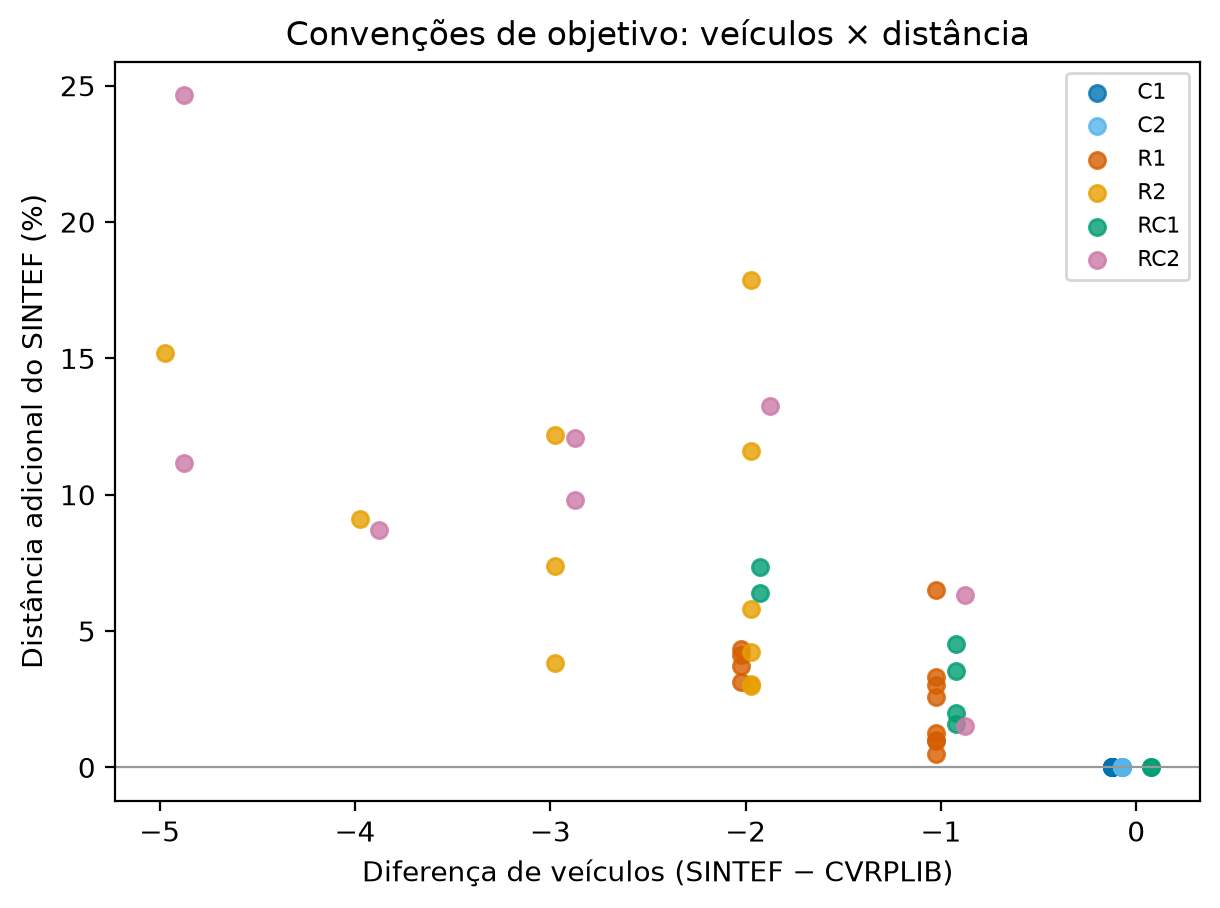

In [5]:
conv = eda.convention_comparison(instances, sintef, cvrplib)
display(eda.localize_columns(eda.convention_summary(conv, LANG), LANG))

viz_eda.plot_convention_tradeoff(conv, LANG)
plt.show()

**Insight.** As 56 soluções do CVRPLIB são factíveis com distância truncada e reproduzem o custo publicado em 56 de 56 casos (tolerância de 0,05), o que valida o verificador na convenção do CVRPLIB. Com distância exata, porém, 48 permanecem factíveis e 8 deixam de ser (R102, R105, R107, R108, R112, R211, RC101 e RC105): violam janelas de tempo por diferenças de arredondamento. Entre as convenções, o SINTEF usa menos veículos em 37 instâncias (até 5 a menos) e nunca mais; nessas 37, sua distância é de 0,5% a 24,6% maior do que a das rotas do CVRPLIB recalculadas com distância exata. Em 19 instâncias a frota é igual (todas as C e duas RC1, conforme as cores do gráfico), e nelas a distância do SINTEF é reproduzida a ±0,01 em 19 de 19. No gráfico, as instâncias C ficam em x = 0 e y ≈ 0; os pontos com x negativo são R e RC. **Limitações:** as distâncias exatas das 8 soluções infactíveis são de rotas que violam janelas e portanto não são planos válidos nessa convenção; e o gráfico mostra coincidência entre menos veículos e mais distância, sem estabelecer por si só uma relação causal. **Decisão:** a comparação com o benchmark será feita somente sob a convenção do SINTEF (hierárquica, precisão dupla), com o CVRPLIB em análise secundária e tabelas separadas.

## 6. Implicações e decisões

1. **Duas camadas que não se misturam.** *Camada A — benchmark:* VRPTW rígido de Solomon, objetivo lexicográfico (veículos, depois distância), referência SINTEF; violações e clientes não atendidos devem ser zero. *Camada B — cenários de negócio:* variações como janelas flexíveis, prioridade de clientes e perturbações, com custo ponderado declarado; **não** se calcula gap contra o benchmark.
2. **Comparação somente sob a mesma convenção.** Resultados deste projeto serão comparados com a referência SINTEF (hierárquica, precisão dupla); o CVRPLIB serve apenas como análise secundária, em tabelas separadas.
3. **Sem alegações de otimalidade.** As referências do SINTEF são as melhores soluções conhecidas, obtidas por heurísticas; o gap de distância só é reportado quando a frota é igual à da referência.
4. **Divisão desenvolvimento/avaliação pré-registrada (Nosek et al., 2018).** Ajustes de configuração usam apenas as instâncias de desenvolvimento; as demais ficam reservadas para a avaliação final.
5. **Desvio da regra da pré-análise (registrado em 2026-11-18).** A pré-análise previa que os valores publicados do SINTEF das instâncias de avaliação só seriam lidos no torneio final. Os notebooks 01 e 02 leem os 56 valores publicados, de avaliação inclusive, de forma descritiva (convenções de objetivo e limites de frota); esses valores não foram usados para escolher configuração, orçamento ou parâmetro.
6. **Próximo passo:** o notebook 02 explora a estrutura das instâncias (geografia, janelas, capacidade e compatibilidade temporal) sem usar resultados de solver.

**Pergunta:** quantas instâncias de cada família pertencem a cada conjunto? A tabela mostra a divisão registrada em `data/reference/split.csv`.

In [6]:
split = benchmark.read_split(P["split"])
display(eda.localize_columns(eda.split_summary(split), LANG))

,Família,Desenvolvimento,Avaliação,Total
0,C1,2,7,9
1,C2,2,6,8
2,R1,3,9,12
3,R2,3,8,11
4,RC1,2,6,8
5,RC2,2,6,8
6,Total,14,42,56


**Insight.** O sorteio estratificado reservou 14 instâncias para desenvolvimento e 42 para avaliação (C1: 2/7, C2: 2/6, R1: 3/9, R2: 3/8, RC1: 2/6, RC2: 2/6). Com apenas 2 ou 3 instâncias de desenvolvimento por família, conclusões tiradas delas são frágeis e devem ser tratadas como indicações para a configuração, não como resultado. **Limitação:** o notebook 02 usa as entradas das 56 instâncias, e a seção de frota usa a contagem de veículos de referência também das de avaliação; isso é informação publicada, não resultado de solver, e não será usada para ajustar configurações. **Próximo passo:** o notebook 02 explora a estrutura das instâncias sem resultados de solver.

## Referências

- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- CVRPLIB. (s.d.). *VRPTW instances — Solomon set*. PUC-Rio. https://galgos.inf.puc-rio.br/cvrplib/
- Dantzig, G. B., & Ramser, J. H. (1959). The truck dispatching problem. *Management Science, 6*(1), 80–91.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.